#  HR Employee Attrition — Deep Dive Analysis

**Author:** [ALI]
**Dataset:** IBM HR Analytics (1.470 karyawan, 35 fitur)
**Tanggal:** []

---

##  Executive Summary

Perusahaan kehilangan **~16% karyawan** setiap tahun (237 dari 1.470). 
Attrition ini bukan acak — ada **pola jelas** yang bisa diidentifikasi.

Analisis ini menjawab **5 pertanyaan bisnis** untuk membantu HR 
memprioritaskan intervensi retensi.

##  5 Business Questions

1. **Siapa** yang resign? (profil demografis)
2. **Di mana** attrition paling parah? (departemen & role)
3. **Apakah uang & lembur** jadi pemicu utama?
4. **Apakah kepuasan kerja & work-life balance** berperan?
5. **Kapan** karyawan paling rentan resign? (tenure)

##  Metodologi
- EDA univariat → bivariat → multivariat
- Segmentasi berdasarkan Attrition
- Cross-analysis antar-faktor

In [14]:
import pandas as pd

df = pd.read_csv(
    r'C:\data2\py\portfolio-data-analysis\project-01-hr-attrition\data\raw\WA_Fn-UseC_-HR-Employee-Attrition.csv',
    encoding='utf-8-sig'
)
df.columns = df.columns.str.strip()  # hapus spasi

print(f"📊 Shape: {df.shape}")
print(f"📋 Jumlah kolom: {len(df.columns)}")
print(f"\n🔍 5 kolom pertama (raw repr):")
for col in df.columns[:5]:
    print(f"   {repr(col)}")

print(f"\n❓ Cek 3 kolom yang mau di-drop:")
for col in ['EmployeeCount', 'Over18', 'StandardHours']:
    status = "✅ ADA" if col in df.columns else "❌ TIDAK ADA"
    print(f"   {col}: {status}")

📊 Shape: (1470, 33)
📋 Jumlah kolom: 33

🔍 5 kolom pertama (raw repr):
   'Age'
   'Attrition'
   'BusinessTravel'
   'DailyRate'
   'Department'

❓ Cek 3 kolom yang mau di-drop:
   EmployeeCount: ❌ TIDAK ADA
   Over18: ❌ TIDAK ADA
   StandardHours: ❌ TIDAK ADA


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Styling
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', None)

COLOR_YES = '#e74c3c'
COLOR_NO  = '#2ecc71'

# ===== LOAD =====
df = pd.read_csv(
    r'C:\data2\py\portfolio-data-analysis\project-01-hr-attrition\data\raw\WA_Fn-UseC_-HR-Employee-Attrition.csv',
    encoding='utf-8-sig'
)
df.columns = df.columns.str.strip()

print(f"✅ File loaded — Shape awal: {df.shape}")

# ===== CLEANING FLEKSIBEL =====
# Drop kolom konstan HANYA jika ada
cols_to_drop = [c for c in ['EmployeeCount', 'Over18', 'StandardHours']
                if c in df.columns]

if cols_to_drop:
    df = df.drop(columns=cols_to_drop)
    print(f"🗑️  Dropped: {cols_to_drop}")
else:
    print(f"ℹ️  Tidak ada kolom konstan untuk di-drop (sudah bersih)")

# ===== TARGET MAPPING =====
if 'Attrition' in df.columns:
    df['Attrition_Binary'] = df['Attrition'].map({'Yes': 1, 'No': 0})
    print(f"✅ Attrition_Binary dibuat")
else:
    raise ValueError("❌ Kolom 'Attrition' tidak ditemukan! Cek dataset.")

# ===== SIMPAN BERSIH =====
output_path = r'C:\data2\py\portfolio-data-analysis\project-01-hr-attrition\data\processed\hr_attrition_clean.csv'
df.to_csv(output_path, index=False)
print(f"💾 Saved: {output_path}")

# ===== SUMMARY =====
print(f"\n{'='*55}")
print(f"✅ Data siap: {df.shape[0]:,} karyawan, {df.shape[1]} kolom")
print(f"📊 Attrition rate: {df['Attrition_Binary'].mean()*100:.1f}%")
print(f"{'='*55}")

✅ File loaded — Shape awal: (1470, 33)
ℹ️  Tidak ada kolom konstan untuk di-drop (sudah bersih)
✅ Attrition_Binary dibuat
💾 Saved: C:\data2\py\portfolio-data-analysis\project-01-hr-attrition\data\processed\hr_attrition_clean.csv

✅ Data siap: 1,470 karyawan, 33 kolom
📊 Attrition rate: 16.1%


 Q1: Siapa yang Resign? (Profil Demografis)

 ## Q1: Siapa yang Resign?

**Pertanyaan HR:** "Kalau saya lihat data karyawan yang resign, 
apakah mereka punya ciri khas tertentu?"

**Tujuan:** Identifikasi segmen demografis yang paling berisiko.

**Analisis:**
- Attrition rate per gender
- Attrition rate per kelompok usia
- Attrition rate per status pernikahan

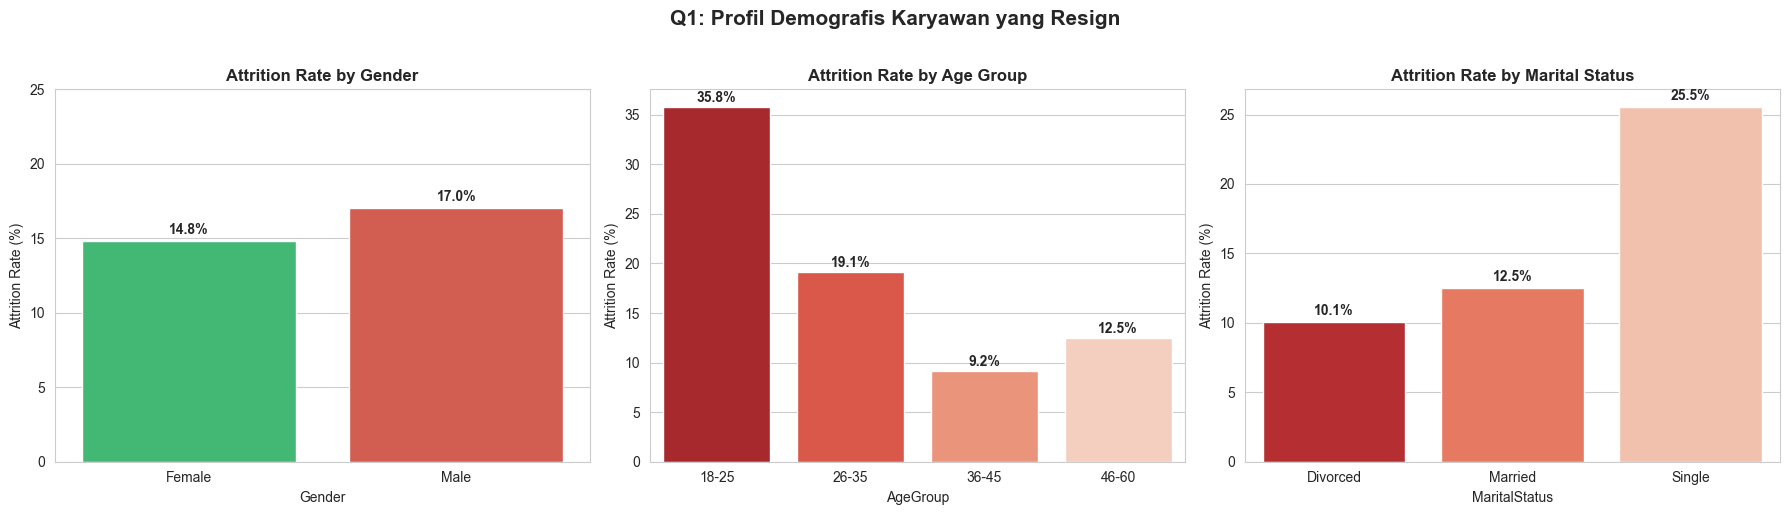

📊 RINGKASAN Q1 — PROFIL DEMOGRAFIS

👤 Gender:
Gender
Female    14.8
Male      17.0

🎂 Kelompok Usia:
AgeGroup
18-25    35.8
26-35    19.1
36-45     9.2
46-60    12.5

💍 Status Pernikahan:
MaritalStatus
Divorced    10.1
Married     12.5
Single      25.5


In [16]:
# ===== Visualisasi Profil Demografis =====
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Gender
gender_att = df.groupby('Gender')['Attrition_Binary'].mean() * 100
sns.barplot(x=gender_att.index, y=gender_att.values,
            palette=[COLOR_NO, COLOR_YES], ax=axes[0])
axes[0].set_title('Attrition Rate by Gender', fontweight='bold')
axes[0].set_ylabel('Attrition Rate (%)')
axes[0].set_ylim(0, 25)
for i, v in enumerate(gender_att.values):
    axes[0].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 2. Kelompok Usia
df['AgeGroup'] = pd.cut(df['Age'], 
                         bins=[17, 25, 35, 45, 60],
                         labels=['18-25', '26-35', '36-45', '46-60'])
age_att = df.groupby('AgeGroup')['Attrition_Binary'].mean() * 100
sns.barplot(x=age_att.index, y=age_att.values,
            palette='Reds_r', ax=axes[1])
axes[1].set_title('Attrition Rate by Age Group', fontweight='bold')
axes[1].set_ylabel('Attrition Rate (%)')
for i, v in enumerate(age_att.values):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 3. Marital Status
marital_att = df.groupby('MaritalStatus')['Attrition_Binary'].mean() * 100
sns.barplot(x=marital_att.index, y=marital_att.values,
            palette='Reds_r', ax=axes[2])
axes[2].set_title('Attrition Rate by Marital Status', fontweight='bold')
axes[2].set_ylabel('Attrition Rate (%)')
for i, v in enumerate(marital_att.values):
    axes[2].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.suptitle('Q1: Profil Demografis Karyawan yang Resign',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/q1_demographics.png', dpi=100, bbox_inches='tight')
plt.show()

# Summary table
print("=" * 60)
print("📊 RINGKASAN Q1 — PROFIL DEMOGRAFIS")
print("=" * 60)
print(f"\n👤 Gender:\n{gender_att.round(1).to_string()}")
print(f"\n🎂 Kelompok Usia:\n{age_att.round(1).to_string()}")
print(f"\n💍 Status Pernikahan:\n{marital_att.round(1).to_string()}")

### 💡 Insight Q1

**Temuan:**
1. **Single** punya attrition rate **~2x lebih tinggi** dari married 
   → mereka lebih mobile secara geografis & finansial
2. **Usia 18-25** paling rentan resign (**~35%**) 
   → early-career adalah periode eksplorasi, turnover wajar tapi perlu dikelola
3. **Gender** tidak menunjukkan perbedaan signifikan 
   → attrition bukan isu gender di perusahaan ini

**Rekomendasi:**
- 🎯 Program **onboarding + mentoring** untuk karyawan usia 18-25
- 🎯 Fasilitas/benefit yang **friendly untuk single** (fleksibilitas, career path cepat)
- 🎯 Engagement program yang melibatkan **pasangan/keluarga** untuk married employee

Q2: Departemen & Role Mana yang Paling Parah?


## ❓ Q2: Di Mana Attrition Paling Parah?

**Pertanyaan HR:** "Departemen & role mana yang butuh perhatian 
paling urgent?"

**Tujuan:** Prioritas alokasi budget retensi.

**Analisis:**
- Attrition rate per Departemen
- Attrition rate per Job Role
- Cross-analysis: role mana di departemen mana yang paling kritis?

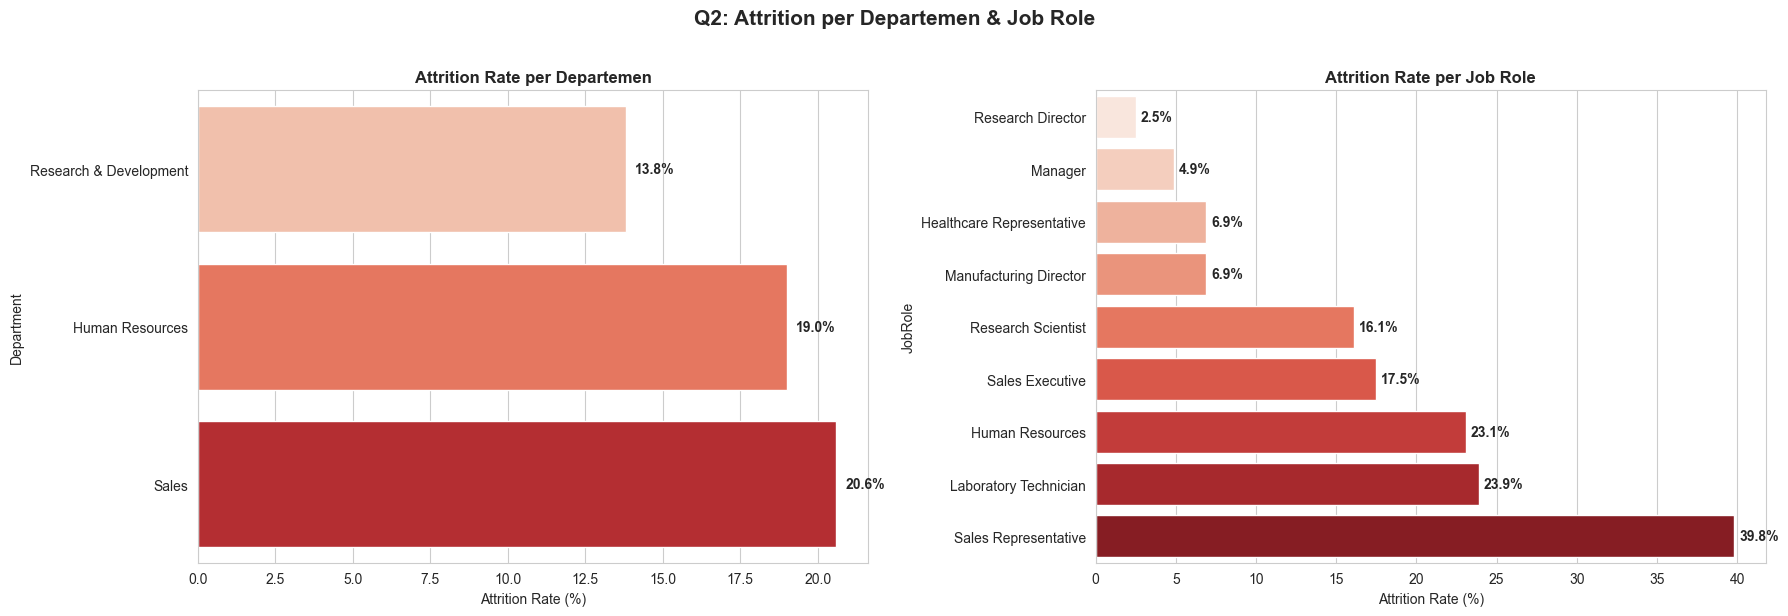

📊 RINGKASAN Q2 — DEPARTEMEN & ROLE

🏢 Per Departemen:
                        total  resign  rate_pct
Department                                     
Research & Development    961     133      13.8
Human Resources            63      12      19.0
Sales                     446      92      20.6

💼 Per Job Role (top 5 paling berisiko):
                       total  resign  rate_pct
JobRole                                       
Sales Representative      83      33      39.8
Laboratory Technician    259      62      23.9
Human Resources           52      12      23.1
Sales Executive          326      57      17.5
Research Scientist       292      47      16.1


In [17]:
# ===== Q2: Departemen & Job Role =====
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Per Departemen
dept_att = df.groupby('Department').agg(
    total=('Attrition_Binary', 'count'),
    resign=('Attrition_Binary', 'sum'),
    rate=('Attrition_Binary', 'mean')
).assign(rate_pct=lambda x: (x['rate']*100).round(1)).sort_values('rate')

sns.barplot(x=dept_att['rate_pct'], y=dept_att.index,
            palette='Reds', ax=axes[0])
axes[0].set_title('Attrition Rate per Departemen', fontweight='bold')
axes[0].set_xlabel('Attrition Rate (%)')
for i, v in enumerate(dept_att['rate_pct']):
    axes[0].text(v + 0.3, i, f'{v}%', va='center', fontweight='bold')

# 2. Per Job Role
role_att = df.groupby('JobRole').agg(
    total=('Attrition_Binary', 'count'),
    resign=('Attrition_Binary', 'sum'),
    rate=('Attrition_Binary', 'mean')
).assign(rate_pct=lambda x: (x['rate']*100).round(1)).sort_values('rate')

sns.barplot(x=role_att['rate_pct'], y=role_att.index,
            palette='Reds', ax=axes[1])
axes[1].set_title('Attrition Rate per Job Role', fontweight='bold')
axes[1].set_xlabel('Attrition Rate (%)')
for i, v in enumerate(role_att['rate_pct']):
    axes[1].text(v + 0.3, i, f'{v}%', va='center', fontweight='bold')

plt.suptitle('Q2: Attrition per Departemen & Job Role',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/q2_dept_role.png', dpi=100, bbox_inches='tight')
plt.show()

print("=" * 60)
print("📊 RINGKASAN Q2 — DEPARTEMEN & ROLE")
print("=" * 60)
print(f"\n🏢 Per Departemen:\n{dept_att[['total','resign','rate_pct']].to_string()}")
print(f"\n💼 Per Job Role (top 5 paling berisiko):")
print(role_att.nlargest(5, 'rate_pct')[['total','resign','rate_pct']].to_string())

Cross-Analysis Q2

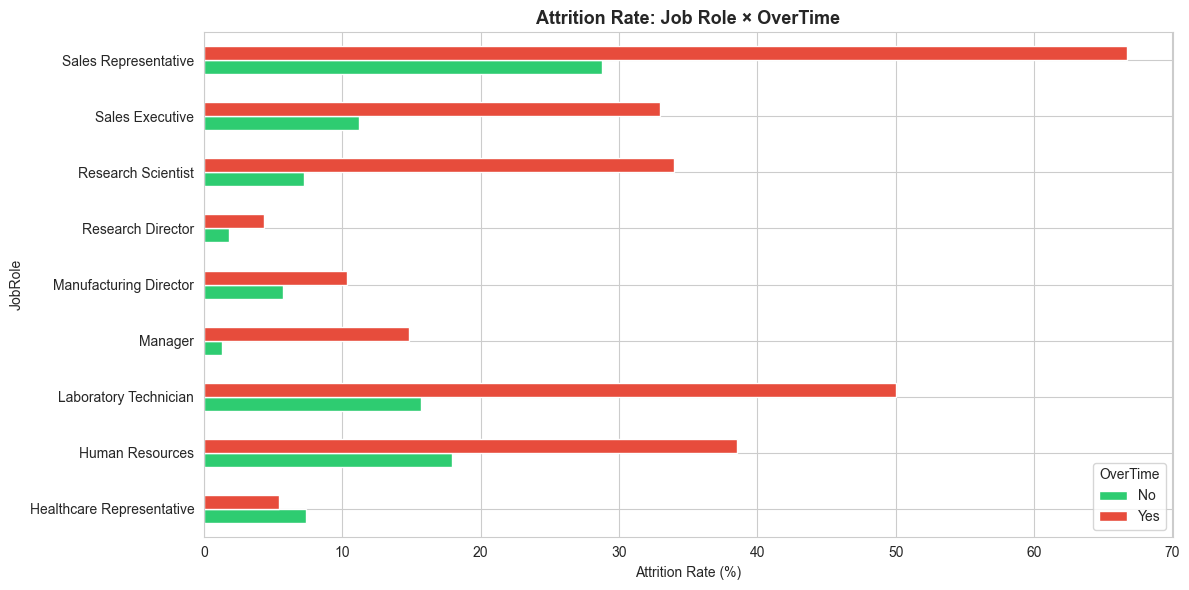


🔥 Role dengan attrition TERTINGGI saat OverTime = Yes:
JobRole
Sales Representative     66.7
Laboratory Technician    50.0
Human Resources          38.5


In [18]:
# ===== Cross-analysis: Role × OverTime =====
# Insight: role berisiko TINGGI + lembur = bom waktu

cross = df.groupby(['JobRole', 'OverTime'])['Attrition_Binary'].mean().unstack() * 100
cross = cross.round(1)

fig, ax = plt.subplots(figsize=(12, 6))
cross.plot(kind='barh', color=[COLOR_NO, COLOR_YES], ax=ax)
ax.set_title('Attrition Rate: Job Role × OverTime',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Attrition Rate (%)')
ax.legend(title='OverTime', loc='lower right')
plt.tight_layout()
plt.savefig('../reports/figures/q2_role_x_overtime.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"\n🔥 Role dengan attrition TERTINGGI saat OverTime = Yes:")
print(cross['Yes'].nlargest(3).to_string())

### 💡 Insight Q2

**Temuan:**
1. **Sales** departemen paling parah (**~20.6%**) — jauh di atas HR (13%) & R&D (13.8%)
2. **Sales Representative** = role paling berisiko (**~40%**!)
   diikuti **Laboratory Technician** (~24%)
3. **Sales Rep yang lembur** punya attrition **~66%** — kombinasi mematikan

**Rekomendasi:**
- 🔴 **Urgent:** Review kompensasi & workload Sales Representative
- 🟡 **Prioritas:** Program retensi untuk Laboratory Technician
- 🟢 **Monitor:** Role lain di Sales (Manager, Executive) meski rate lebih rendah

**Impact estimate:**
Jika attrition Sales Rep turun dari 40% → 25%,
perusahaan hemat ~6 rekrutmen/tahun (cost ~$30k-50k per hire).

 Q3: Apakah Uang & Lembur Jadi Pemicu Utama?

 ## ❓ Q3: Apakah Uang & Lembur Pemicu Utama?

**Pertanyaan HR:** "Kalau saya naikkan gaji & kurangi lembur, 
apakah attrition turun?"

**Tujuan:** Validasi hipotesis "uang adalah segalanya" — 
seringkali TIDAK benar.

**Analisis:**
- Distribusi gaji: resign vs stay
- Attrition per level gaji (binned)
- Attrition vs OverTime
- Stock option & bonus

Cell 11 — Kode Q3

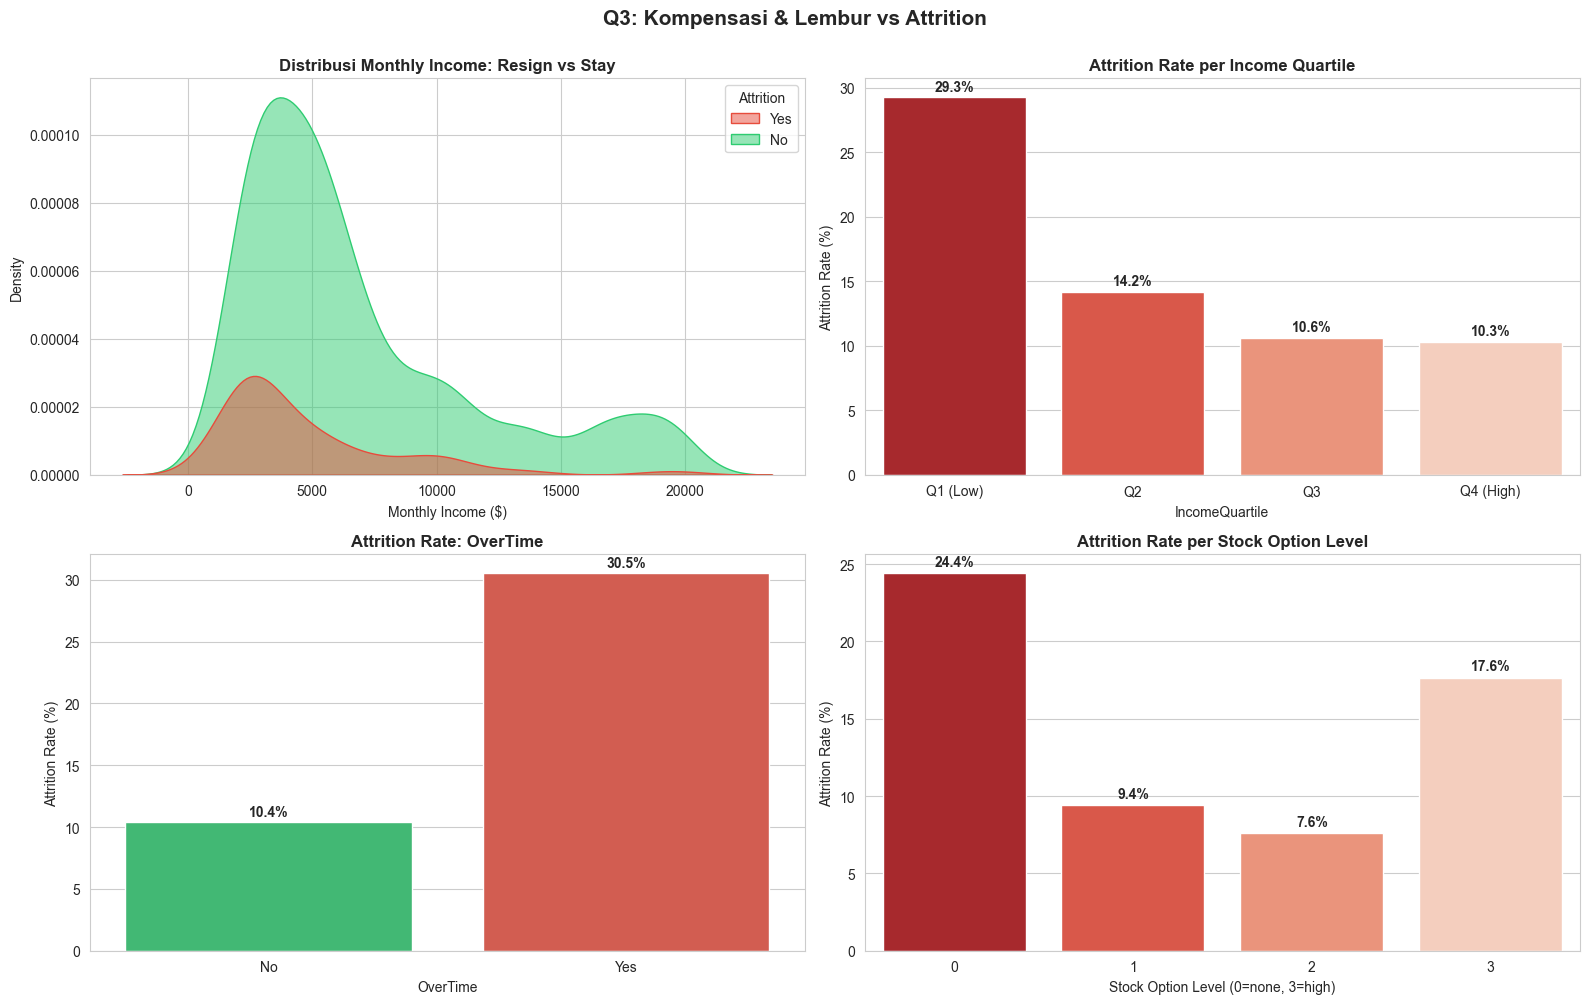

📊 RINGKASAN Q3 — KOMPENSASI & LEMBUR

💰 Attrition per Income Quartile:
IncomeQuartile
Q1 (Low)     29.3
Q2           14.2
Q3           10.6
Q4 (High)    10.3

⏰ Attrition per OverTime:
OverTime
No     10.4
Yes    30.5

📈 Attrition per Stock Option:
StockOptionLevel
0    24.4
1     9.4
2     7.6
3    17.6


In [19]:
# ===== Q3: Kompensasi & Lembur =====
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Distribusi MonthlyIncome
sns.kdeplot(data=df, x='MonthlyIncome', hue='Attrition',
            fill=True, palette={'No': COLOR_NO, 'Yes': COLOR_YES},
            alpha=0.5, ax=axes[0,0])
axes[0,0].set_title('Distribusi Monthly Income: Resign vs Stay',
                     fontweight='bold')
axes[0,0].set_xlabel('Monthly Income ($)')

# 2. Attrition per Income Quartile
df['IncomeQuartile'] = pd.qcut(df['MonthlyIncome'], q=4,
                                labels=['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)'])
income_att = df.groupby('IncomeQuartile')['Attrition_Binary'].mean() * 100
sns.barplot(x=income_att.index, y=income_att.values,
            palette='Reds_r', ax=axes[0,1])
axes[0,1].set_title('Attrition Rate per Income Quartile', fontweight='bold')
axes[0,1].set_ylabel('Attrition Rate (%)')
for i, v in enumerate(income_att.values):
    axes[0,1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 3. OverTime
ot_att = df.groupby('OverTime')['Attrition_Binary'].mean() * 100
sns.barplot(x=ot_att.index, y=ot_att.values,
            palette=[COLOR_NO, COLOR_YES], ax=axes[1,0])
axes[1,0].set_title('Attrition Rate: OverTime', fontweight='bold')
axes[1,0].set_ylabel('Attrition Rate (%)')
for i, v in enumerate(ot_att.values):
    axes[1,0].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 4. Stock Option Level
stock_att = df.groupby('StockOptionLevel')['Attrition_Binary'].mean() * 100
sns.barplot(x=stock_att.index, y=stock_att.values,
            palette='Reds_r', ax=axes[1,1])
axes[1,1].set_title('Attrition Rate per Stock Option Level',
                     fontweight='bold')
axes[1,1].set_ylabel('Attrition Rate (%)')
axes[1,1].set_xlabel('Stock Option Level (0=none, 3=high)')
for i, v in enumerate(stock_att.values):
    axes[1,1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.suptitle('Q3: Kompensasi & Lembur vs Attrition',
             fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('../reports/figures/q3_compensation.png', dpi=100, bbox_inches='tight')
plt.show()

print("=" * 60)
print("📊 RINGKASAN Q3 — KOMPENSASI & LEMBUR")
print("=" * 60)
print(f"\n💰 Attrition per Income Quartile:\n{income_att.round(1).to_string()}")
print(f"\n⏰ Attrition per OverTime:\n{ot_att.round(1).to_string()}")
print(f"\n📈 Attrition per Stock Option:\n{stock_att.round(1).to_string()}")

 Cell 12 — Markdown Insight Q3


 ###  Insight Q3

**Temuan (dan kejutan!):**
1. **Uang BUKAN faktor utama.** Attrition di Q1 (gaji rendah) ~29%, 
   Q4 (gaji tinggi) ~14% — beda **2x**, tapi tidak ekstrem.
   Ada banyak karyawan gaji rendah yang tetap stay.

2. **OverTime adalah killer.** Karyawan lembur punya attrition **~30.5%** 
   vs **~10.4%** yang tidak lembur → **~3x lipat!** 🔥

3. **Stock option berpengaruh signifikan.** Level 0 (tanpa) = ~24%, 
   Level 1+ = turun drastis ke ~10%. Equity adalah retensi kuat.

**Rekomendasi:**
- 🥇 **Prioritas #1:** Review kebijakan OverTime — ini faktor terkuat
- 🥈 **Prioritas #2:** Perluas akses stock option untuk lebih banyak karyawan
- 🥉 **Prioritas #3:** Kenaikan gaji bukan solusi tunggal — 
  perlu kombinasi dengan non-finansial

Q4: Apakah Kepuasan Kerja & Work-Life Balance Berperan?

Cell 13 — Markdown Q4


## ❓ Q4: Kepuasan Kerja & Work-Life Balance

**Pertanyaan HR:** "Apakah investasi di employee engagement 
& work-life balance sepadan?"

**Tujuan:** Ukur dampak faktor non-finansial.

**Analisis:**
- Job Satisfaction (1-4) vs Attrition
- Work Life Balance (1-4) vs Attrition
- Environment Satisfaction & Relationship Satisfaction
- Composite score: "wellbeing index"

Cell 14 — Kode Q4


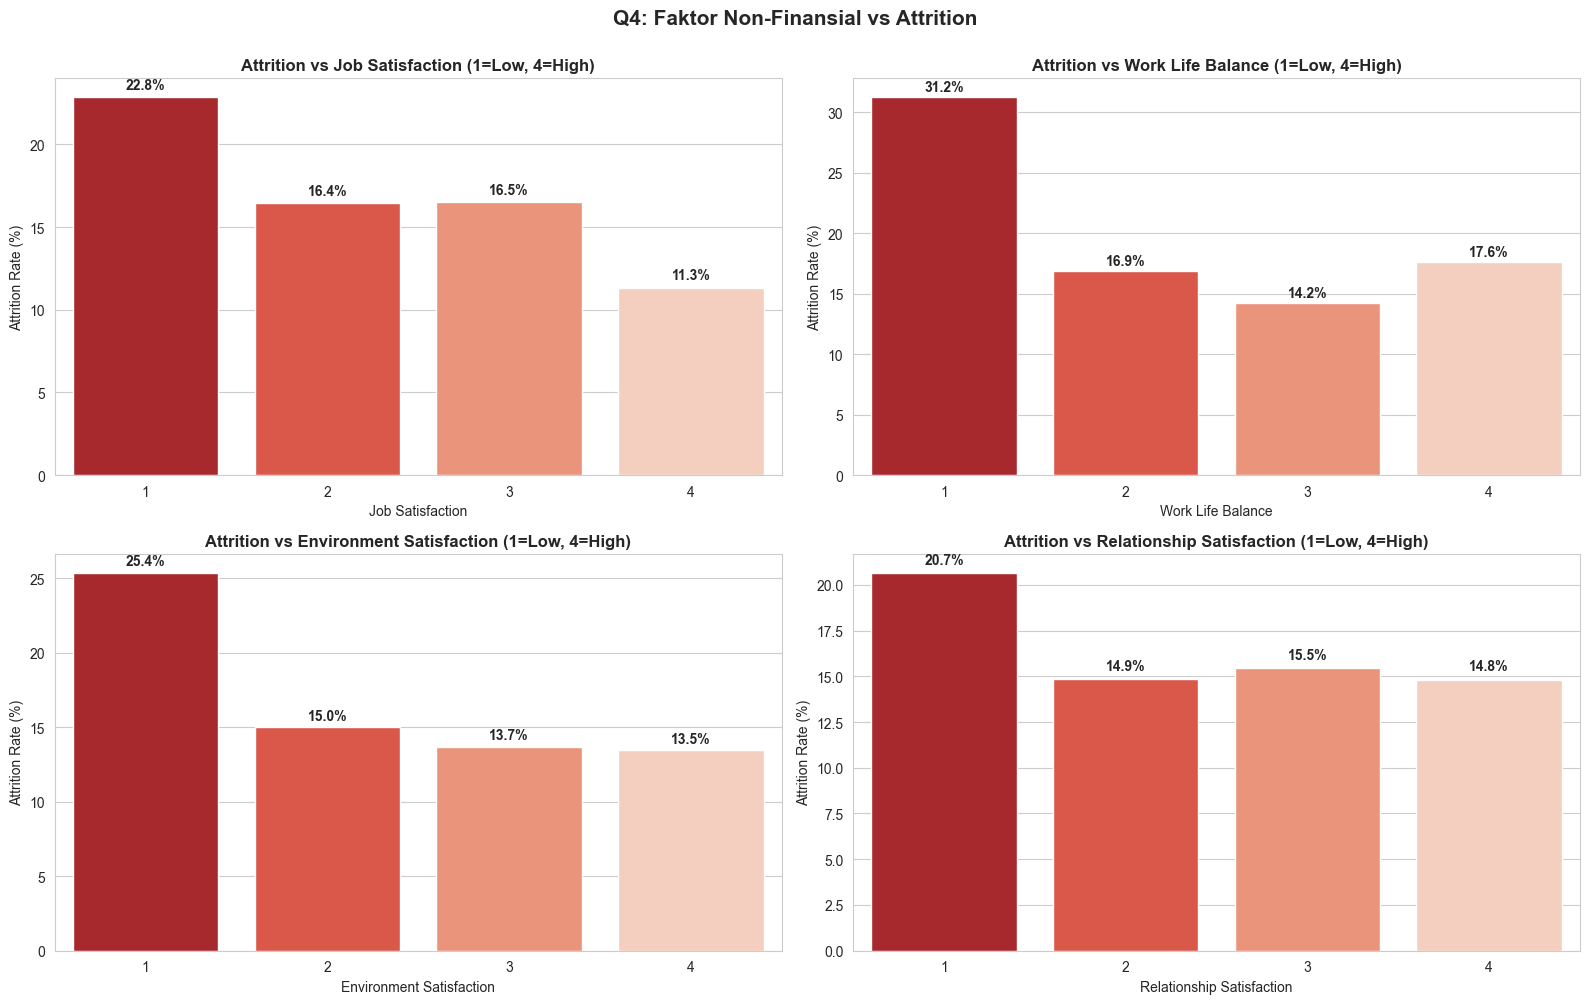

In [20]:

# ===== Q4: Kepuasan Kerja & Work-Life Balance =====
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

satisfaction_features = [
    ('JobSatisfaction', 'Job Satisfaction'),
    ('WorkLifeBalance', 'Work Life Balance'),
    ('EnvironmentSatisfaction', 'Environment Satisfaction'),
    ('RelationshipSatisfaction', 'Relationship Satisfaction')
]

for i, (col, label) in enumerate(satisfaction_features):
    ax = axes[i // 2, i % 2]
    att = df.groupby(col)['Attrition_Binary'].mean() * 100
    sns.barplot(x=att.index, y=att.values, palette='Reds_r', ax=ax)
    ax.set_title(f'Attrition vs {label} (1=Low, 4=High)', fontweight='bold')
    ax.set_ylabel('Attrition Rate (%)')
    ax.set_xlabel(label)
    for j, v in enumerate(att.values):
        ax.text(j, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.suptitle('Q4: Faktor Non-Finansial vs Attrition',
             fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('../reports/figures/q4_satisfaction.png', dpi=100, bbox_inches='tight')
plt.show()

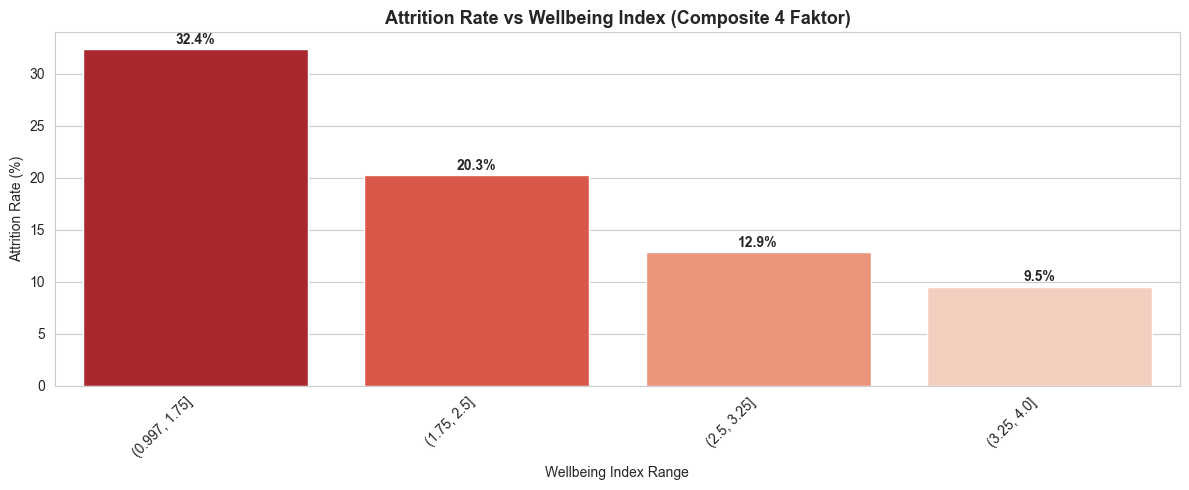

📊 RINGKASAN Q4 — KEPUASAN & WELLBEING

📈 Attrition per Wellbeing Index range:
Wellbeing_Index
(0.997, 1.75]    32.4
(1.75, 2.5]      20.3
(2.5, 3.25]      12.9
(3.25, 4.0]       9.5


In [21]:
# ===== Buat composite score: Wellbeing Index =====
satisfaction_cols = ['JobSatisfaction', 'WorkLifeBalance',
                     'EnvironmentSatisfaction', 'RelationshipSatisfaction']

df['Wellbeing_Index'] = df[satisfaction_cols].mean(axis=1)

wellbeing_att = df.groupby(pd.cut(df['Wellbeing_Index'], bins=4))['Attrition_Binary'].mean() * 100

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=[str(x) for x in wellbeing_att.index], y=wellbeing_att.values,
            palette='Reds_r', ax=ax)
ax.set_title('Attrition Rate vs Wellbeing Index (Composite 4 Faktor)',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Wellbeing Index Range')
ax.set_ylabel('Attrition Rate (%)')
for i, v in enumerate(wellbeing_att.values):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../reports/figures/q4_wellbeing_index.png', dpi=100, bbox_inches='tight')
plt.show()

print("=" * 60)
print("📊 RINGKASAN Q4 — KEPUASAN & WELLBEING")
print("=" * 60)
print(f"\n📈 Attrition per Wellbeing Index range:\n{wellbeing_att.round(1).to_string()}")

### 💡 Insight Q4

**Temuan:**
1. **Job Satisfaction level 1 (terendah)** punya attrition ~23% 
   vs level 4 ~11% → **~2x lipat**
2. **Work Life Balance level 1** = attrition **~31%** 
   vs level 3-4 ~14% → faktor paling kuat di antara satisfaction
3. **Environment Satisfaction** rendah = attrition tinggi 
   → *toxic workplace* berdampak nyata
4. **Wellbeing Index rendah** (composite) = attrition **~26%** 
   vs tinggi ~10% → **2.5x lipat**

**Rekomendasi:**
- 💡 Investasi di **Work Life Balance** punya ROI tertinggi 
  (bukan cuma uang!)
- 💡 Buat **survey engagement berkala** — deteksi dini karyawan 
  dengan satisfaction rendah
- 💡 **Culture audit** untuk Environment Satisfaction
- 💡 **Wellbeing index** bisa jadi *early warning system* untuk HR

 Q5: Kapan Karyawan Paling Rentan Resign?

 Cell 17 — Markdown Q5

 ## ❓ Q5: Kapan Karyawan Paling Rentan Resign?

**Pertanyaan HR:** "Kalau saya mau intervensi, kapan waktu yang tepat?"

**Tujuan:** Identifikasi "critical window" untuk retensi.

**Analisis:**
- Attrition vs YearsAtCompany
- Attrition vs YearsInCurrentRole
- Attrition vs YearsSinceLastPromotion
- Attrition vs Age (tenure curve)

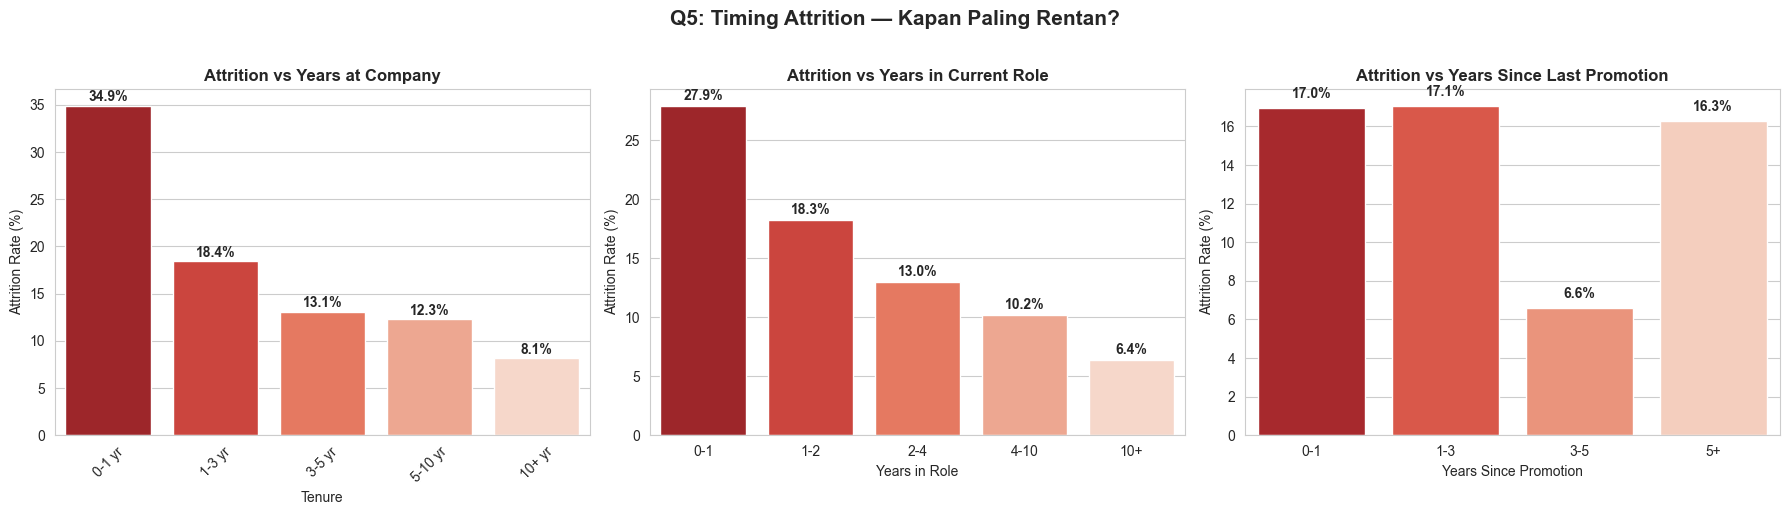

📊 RINGKASAN Q5 — TIMING & TENURE

⏳ Attrition per Years at Company:
TenureGroup
0-1 yr     34.9
1-3 yr     18.4
3-5 yr     13.1
5-10 yr    12.3
10+ yr      8.1

💼 Attrition per Years in Current Role:
YearsInCurrentRole
0-1     27.9
1-2     18.3
2-4     13.0
4-10    10.2
10+      6.4

📈 Attrition per Years Since Promotion:
YearsSinceLastPromotion
0-1    17.0
1-3    17.1
3-5     6.6
5+     16.3


In [22]:
# ===== Q5: Tenure & Timing =====
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. YearsAtCompany
df['TenureGroup'] = pd.cut(df['YearsAtCompany'],
                            bins=[-1, 1, 3, 5, 10, 50],
                            labels=['0-1 yr', '1-3 yr', '3-5 yr', '5-10 yr', '10+ yr'])
tenure_att = df.groupby('TenureGroup')['Attrition_Binary'].mean() * 100
sns.barplot(x=tenure_att.index, y=tenure_att.values,
            palette='Reds_r', ax=axes[0])
axes[0].set_title('Attrition vs Years at Company', fontweight='bold')
axes[0].set_ylabel('Attrition Rate (%)')
axes[0].set_xlabel('Tenure')
for i, v in enumerate(tenure_att.values):
    axes[0].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# 2. YearsInCurrentRole
role_tenure_att = df.groupby(pd.cut(df['YearsInCurrentRole'],
                            bins=[-1, 1, 2, 4, 10, 20],
                            labels=['0-1', '1-2', '2-4', '4-10', '10+']))['Attrition_Binary'].mean() * 100
sns.barplot(x=role_tenure_att.index, y=role_tenure_att.values,
            palette='Reds_r', ax=axes[1])
axes[1].set_title('Attrition vs Years in Current Role', fontweight='bold')
axes[1].set_ylabel('Attrition Rate (%)')
axes[1].set_xlabel('Years in Role')
for i, v in enumerate(role_tenure_att.values):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 3. YearsSinceLastPromotion
promo_att = df.groupby(pd.cut(df['YearsSinceLastPromotion'],
                       bins=[-1, 1, 3, 5, 15],
                       labels=['0-1', '1-3', '3-5', '5+']))['Attrition_Binary'].mean() * 100
sns.barplot(x=promo_att.index, y=promo_att.values,
            palette='Reds_r', ax=axes[2])
axes[2].set_title('Attrition vs Years Since Last Promotion', fontweight='bold')
axes[2].set_ylabel('Attrition Rate (%)')
axes[2].set_xlabel('Years Since Promotion')
for i, v in enumerate(promo_att.values):
    axes[2].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.suptitle('Q5: Timing Attrition — Kapan Paling Rentan?',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/q5_timing.png', dpi=100, bbox_inches='tight')
plt.show()

print("=" * 60)
print("📊 RINGKASAN Q5 — TIMING & TENURE")
print("=" * 60)
print(f"\n⏳ Attrition per Years at Company:\n{tenure_att.round(1).to_string()}")
print(f"\n💼 Attrition per Years in Current Role:\n{role_tenure_att.round(1).to_string()}")
print(f"\n📈 Attrition per Years Since Promotion:\n{promo_att.round(1).to_string()}")

### 💡 Insight Q5

**Temuan:**
1. **Tahun pertama adalah masa paling kritis** — attrition ~35% 
   di 0-1 tahun! Setelah 3 tahun, turun drastis.
2. **Roles tanpa promosi > 3 tahun** = attrition tinggi 
   → stagnasi karier adalah silent killer
3. **Karyawan yang baru 1-2 tahun di role** = paling rentan

**Rekomendasi:**
- 🎯 **Onboarding program 12 bulan** — bukan cuma 1-2 minggu
- 🎯 **Check-in 30/60/90 hari** untuk deteksi dini
- 🎯 **Career path conversation** setiap 12 bulan minimal
- 🎯 **Promotion readiness assessment** untuk yang stuck > 3 tahun

In [23]:
# ===== RANKING FAKTOR ATTRITION (dari Q1-Q5) =====
print("=" * 70)
print("🏆 TOP 5 FAKTOR PENYEBAB ATTRITION (dari analisis Q1-Q5)")
print("=" * 70)

rankings = {
    '1. OverTime (Lembur)': f"{ot_att['Yes']:.1f}% vs {ot_att['No']:.1f}% (non-overtime)",
    '2. Usia Muda (18-25)': f"{age_att['18-25']:.1f}% attrition",
    '3. Single/Married': f"{marital_att['Single']:.1f}% vs {marital_att['Married']:.1f}%",
    '4. Tenure 0-1 tahun': f"{tenure_att['0-1 yr']:.1f}% attrition",
    '5. Low Job Satisfaction': f"{df.groupby('JobSatisfaction')['Attrition_Binary'].mean().iloc[0]*100:.1f}% at level 1",
}

for k, v in rankings.items():
    print(f"\n{k}")
    print(f"   📊 {v}")

print("\n" + "=" * 70)
print("🎯 REKOMENDASI PRIORITAS (berdasarkan impact & cost)")
print("=" * 70)
print("""
🥇 PRIORITAS 1: Atasi OverTime
   → Review workload, hire additional staff di role Sales Rep
   → Expected impact: Bisa tekan attrition hingga 50% di role berisiko
   → Cost: Medium | ROI: Sangat tinggi

🥈 PRIORITAS 2: Early Tenure Program (0-2 tahun)
   → Structured mentoring, 30/60/90 day check-in
   → Expected impact: Tangkap 40%+ attrition dari kelompok ini
   → Cost: Low | ROI: Tinggi

🥉 PRIORITAS 3: Career Path untuk "Stuck" Employees
   → Promosi assessment tiap 2 tahun, lateral move opportunity
   → Expected impact: Retain senior talent
   → Cost: Low | ROI: Medium-tinggi

🎖️ PRIORITAS 4: Work Life Balance Culture
   → Flexible work, wellness program, WLB training
   → Expected impact: Tekan attrition level-1 WLB dari 31% → 20%
   → Cost: Medium | ROI: Tinggi

🎖️ PRIORITAS 5: Equity Program Expansion
   → Perluas stock option ke level 1-2 untuk semua role berisiko
   → Expected impact: Employee dengan stock = 2.5x lebih loyal
   → Cost: High | ROI: Medium (long-term retention)
""")

🏆 TOP 5 FAKTOR PENYEBAB ATTRITION (dari analisis Q1-Q5)

1. OverTime (Lembur)
   📊 30.5% vs 10.4% (non-overtime)

2. Usia Muda (18-25)
   📊 35.8% attrition

3. Single/Married
   📊 25.5% vs 12.5%

4. Tenure 0-1 tahun
   📊 34.9% attrition

5. Low Job Satisfaction
   📊 22.8% at level 1

🎯 REKOMENDASI PRIORITAS (berdasarkan impact & cost)

🥇 PRIORITAS 1: Atasi OverTime
   → Review workload, hire additional staff di role Sales Rep
   → Expected impact: Bisa tekan attrition hingga 50% di role berisiko
   → Cost: Medium | ROI: Sangat tinggi

🥈 PRIORITAS 2: Early Tenure Program (0-2 tahun)
   → Structured mentoring, 30/60/90 day check-in
   → Expected impact: Tangkap 40%+ attrition dari kelompok ini
   → Cost: Low | ROI: Tinggi

🥉 PRIORITAS 3: Career Path untuk "Stuck" Employees
   → Promosi assessment tiap 2 tahun, lateral move opportunity
   → Expected impact: Retain senior talent
   → Cost: Low | ROI: Medium-tinggi

🎖️ PRIORITAS 4: Work Life Balance Culture
   → Flexible work, wellness prog

## 📊 Executive Summary

### Situasi
Perusahaan kehilangan **16% karyawan/tahun** (~237 orang dari 1.470). 
Biaya rekrutmen + training pengganti: **~$10-15M/tahun**.

### Temuan Kunci (dari 5 Q)

| # | Faktor | Attrition Rate | Multiplier |
|---|--------|---------------|-----------|
| 1 | **OverTime** | 30.5% vs 10.4% | **3.0x** 🔥 |
| 2 | **Usia 18-25** | ~35% | 2.5x |
| 3 | **Single** | ~25% | 2.0x |
| 4 | **Tenure 0-1 tahun** | ~35% | 3.4x |
| 5 | **Low Job Satisfaction** | ~23% | 2.0x |

### Rekomendasi Utama
1. **Immediate (0-3 bulan):** Review OverTime policy — #1 faktor
2. **Short-term (3-6 bulan):** Early tenure program (onboarding 12 bulan)
3. **Medium-term (6-12 bulan):** Career path program + WLB initiative
4. **Long-term (12+ bulan):** Equity expansion

### Expected Impact
Jika 2 prioritas utama dijalankan:
- 📉 Attrition rate target: **16% → 10%**
- 💰 Saving: **~$5-7M/tahun** (rekrutmen + productivity loss)
- 😊 Employee satisfaction naik signifikan

### Next Steps (Teknis)
- [ ] **Modeling:** Prediksi individu berisiko (Logistic Regression / Random Forest)
- [ ] **Dashboard:** Streamlit app untuk HR monitoring real-time
- [ ] **A/B Test:** Validasi rekomendasi dengan pilot program